# 07 · CodeFormer: face restoration

**What it is.** CodeFormer (Zhou et al., NeurIPS 2022, `codeformer.pth`, 359 MB) restores a degraded face using a learned codebook; a *fidelity* weight `w` trades realism (low w) against faithfulness to the input (high w). In FaceCloud it runs only when a face is soft, and its output is accepted only if the **identity gate** (SFace similarity >= 0.65 for a restored face) and the geometry gate agree. License: S-Lab (non-commercial research use, recorded in `docs/model-licenses/`).

**How it is scored (ground truth).** Sharp public portraits are softened artificially (gaussian blur + light noise); CodeFormer restores them; compared with the original face: PSNR / SSIM / MAE of the whole picture and **identity similarity** (SFace) of the original face against the degraded and against the restored one. The last number is the one the application's gate uses.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))
from common import *
print("project root:", ROOT)

project root: /Users/Ali/Projects/FaceCloud_backend


In [2]:
from enhancement.codeformer import restore_faces_codeformer
GATE = identity_provider().thresholds()["restore_guard"]
cases = []
for pk in public_stock_ids():
    image = photo(pk, 800); face = largest_face(image)
    if face and face["score"] >= 0.85 and min(face["box"][2:]) >= 110:
        cases.append((pk, image, face))
cases = cases[:6]; print(len(cases), "portraits")
rows, shown = [], []
for pk, truth, face in cases:
    soft = degrade(degrade(truth, "blur", 3), "noise", 4)
    (restored, meta), seconds = timed(lambda: restore_faces_codeformer(soft))
    ref = face_embedding(truth, face)
    sim_soft = face_embedding(soft); sim_new = face_embedding(restored)
    rows.append({"photo": pk, "psnr_soft": round(psnr(truth, soft), 2), "psnr_restored": round(psnr(truth, restored), 2), "ssim_soft": round(ssim(truth, soft), 3), "ssim_restored": round(ssim(truth, restored), 3),
                 "id_soft": round(identity_similarity(ref, sim_soft), 3) if sim_soft is not None else None, "id_restored": round(identity_similarity(ref, sim_new), 3) if sim_new is not None else None,
                 "sharp_x": round(sharpness(restored) / max(sharpness(soft), 1e-6), 2), "seconds": round(seconds, 1)})
    shown.append((truth, soft, restored))
for r in rows: r["passes_gate_0.65"] = (r["id_restored"] or 0) >= GATE
table(rows)

[ WARN:0@0.748] global net_impl_backend.cpp:345 setPreferableTarget Targets are not supported by the new graph engine for now


6 portraits


[ WARN:0@4.254] global net_impl_backend.cpp:345 setPreferableTarget Targets are not supported by the new graph engine for now


[ WARN:0@8.034] global net_impl_backend.cpp:345 setPreferableTarget Targets are not supported by the new graph engine for now
[ WARN:0@8.187] global net_impl_backend.cpp:345 setPreferableTarget Targets are not supported by the new graph engine for now


[ WARN:0@9.441] global net_impl_backend.cpp:345 setPreferableTarget Targets are not supported by the new graph engine for now


[ WARN:0@10.516] global net_impl_backend.cpp:345 setPreferableTarget Targets are not supported by the new graph engine for now


[ WARN:0@11.487] global net_impl_backend.cpp:345 setPreferableTarget Targets are not supported by the new graph engine for now


[ WARN:0@12.474] global net_impl_backend.cpp:345 setPreferableTarget Targets are not supported by the new graph engine for now


photo  psnr_soft  psnr_restored  ssim_soft  ssim_restored  id_soft  id_restored  sharp_x  seconds  passes_gate_0.65
-----  ---------  -------------  ---------  -------------  -------  -----------  -------  -------  ----------------
74     19.17      19.21          0.739      0.745          0.705    0.653        1.18     3.7      True            
78     32.71      33.14          0.854      0.868          0.849    0.875        0.83     1.1      True            
81     33.65      33.0           0.879      0.891          0.778    0.685        0.63     0.9      True            
82     30.56      31.17          0.84       0.859          0.929    0.938        0.82     0.9      True            
83     34.14      34.17          0.876      0.879          0.376    0.61         1.02     0.9      False           
86     30.04      29.74          0.783      0.789          0.971    0.931        0.74     0.9      True            


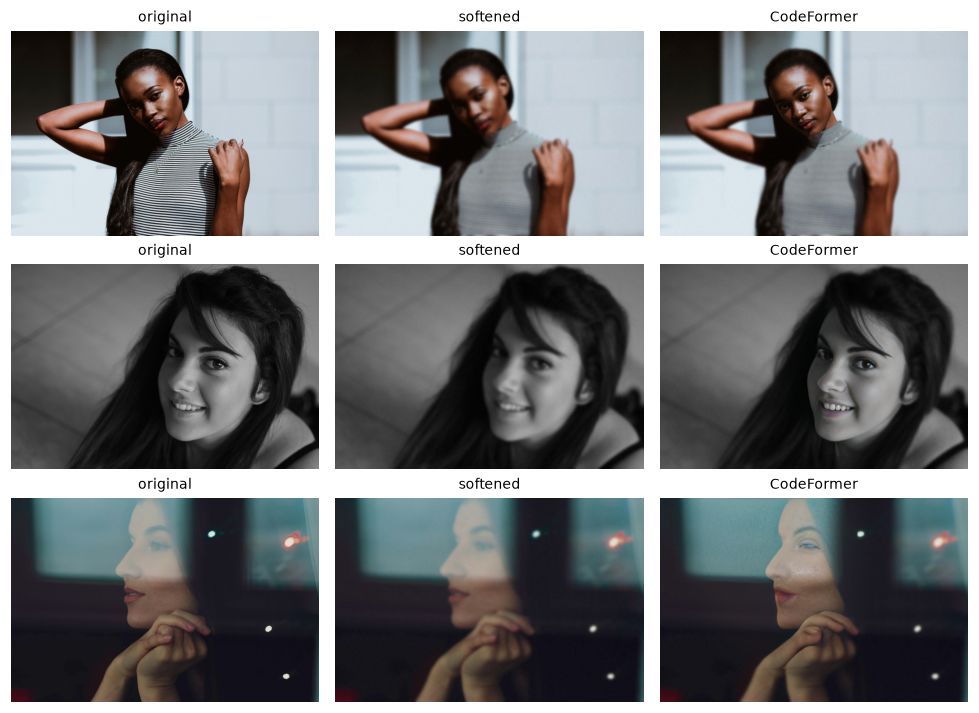

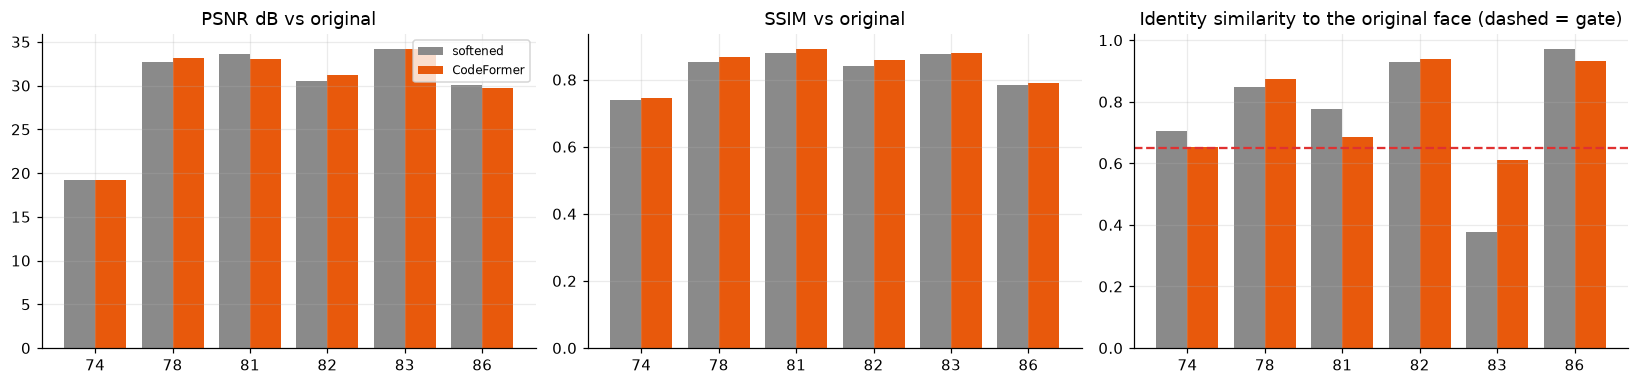

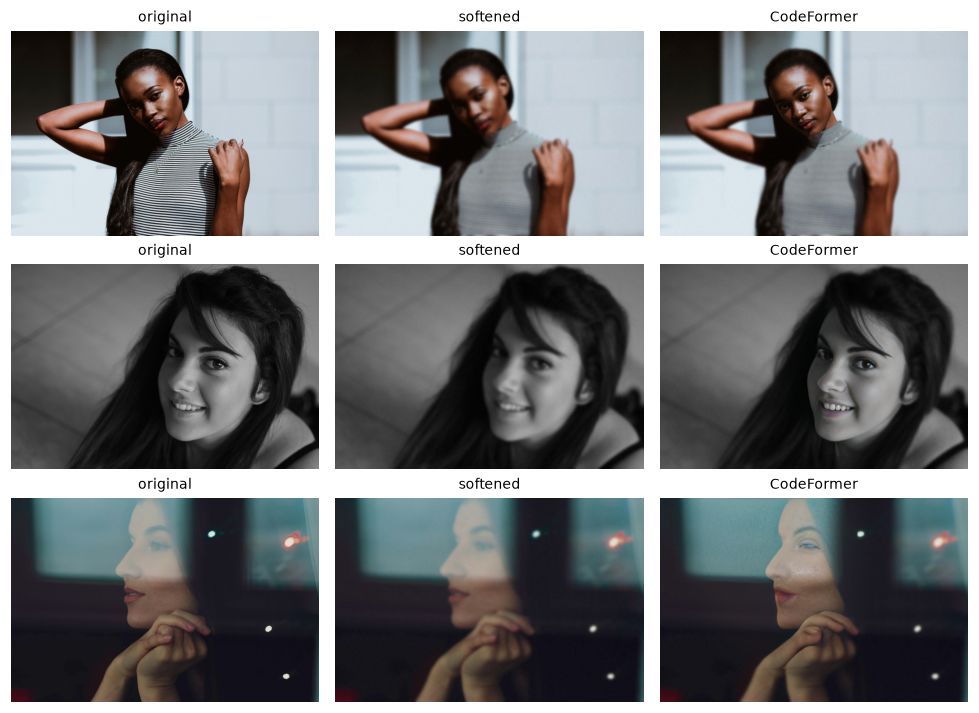

In [3]:
x = np.arange(len(rows)); w = 0.4
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
ax[0].bar(x - w / 2, [r["psnr_soft"] for r in rows], w, label="softened", color=COLORS["input"]); ax[0].bar(x + w / 2, [r["psnr_restored"] for r in rows], w, label="CodeFormer", color=COLORS["model"]); ax[0].set_title("PSNR dB vs original")
ax[1].bar(x - w / 2, [r["ssim_soft"] for r in rows], w, color=COLORS["input"]); ax[1].bar(x + w / 2, [r["ssim_restored"] for r in rows], w, color=COLORS["model"]); ax[1].set_title("SSIM vs original")
ax[2].bar(x - w / 2, [r["id_soft"] or 0 for r in rows], w, color=COLORS["input"]); ax[2].bar(x + w / 2, [r["id_restored"] or 0 for r in rows], w, color=COLORS["model"]); ax[2].axhline(GATE, color=COLORS["bad"], ls="--"); ax[2].set_title("Identity similarity to the original face (dashed = gate)")
for a in ax: a.set_xticks(x, [r["photo"] for r in rows])
ax[0].legend(fontsize=8); fig.tight_layout(); save(fig, "07_codeformer_scores.png")
pick = shown[:3]; fig = montage([i for t in pick for i in t], [n for _ in pick for n in ("original", "softened", "CodeFormer")], columns=3, width=3.0); fig.set_size_inches(9, 2.2 * len(pick)); save(fig, "07_codeformer_examples.png")

## Fidelity sweep: realism against faithfulness (3 portraits)

[ WARN:0@14.955] global net_impl_backend.cpp:345 setPreferableTarget Targets are not supported by the new graph engine for now


[ WARN:0@16.662] global net_impl_backend.cpp:345 setPreferableTarget Targets are not supported by the new graph engine for now


[ WARN:0@17.567] global net_impl_backend.cpp:345 setPreferableTarget Targets are not supported by the new graph engine for now


[ WARN:0@18.505] global net_impl_backend.cpp:345 setPreferableTarget Targets are not supported by the new graph engine for now


[ WARN:0@19.475] global net_impl_backend.cpp:345 setPreferableTarget Targets are not supported by the new graph engine for now


[ WARN:0@20.468] global net_impl_backend.cpp:345 setPreferableTarget Targets are not supported by the new graph engine for now


... (3 outputs left out)

[ WARN:0@24.508] global net_impl_backend.cpp:345 setPreferableTarget Targets are not supported by the new graph engine for now


[ WARN:0@25.527] global net_impl_backend.cpp:345 setPreferableTarget Targets are not supported by the new graph engine for now


[ WARN:0@26.963] global net_impl_backend.cpp:345 setPreferableTarget Targets are not supported by the new graph engine for now


fidelity_w  psnr_db  identity
----------  -------  --------
0.3         27.72    0.644   
0.5         28.14    0.771   
0.7         28.45    0.738   
0.9         28.69    0.824   
{'task': 'face restoration', 'metrics': {'portraits': 6, 'mean_psnr_soft_db': 30.045, 'mean_psnr_restored_db': 30.0717, 'mean_ssim_soft': 0.8285, 'mean_ssim_restored': 0.8385, 'mean_identity_soft': 0.768, 'mean_identity_restored': 0.782, 'share_passing_identity_gate': 0.8333, 'mean_sharpness_gain_x': 0.87, 'mean_seconds': 1.4}, 'note': 'softened portraits with ground truth; identity gate 0.65'}


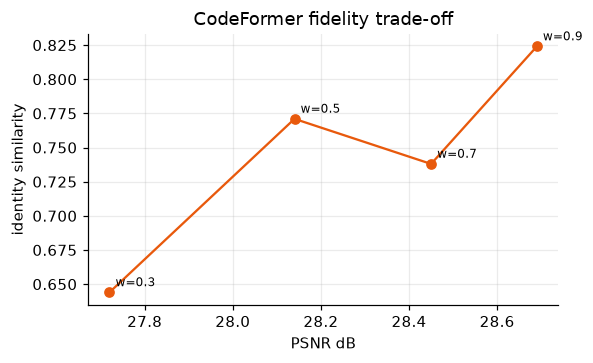

In [4]:
sweep = []
for w_ in (0.3, 0.5, 0.7, 0.9):
    p, i = [], []
    for pk, truth, face in cases[:3]:
        soft = degrade(degrade(truth, "blur", 3), "noise", 4)
        out = first(restore_faces_codeformer(soft, fidelity=w_)); e = face_embedding(out); ref = face_embedding(truth, face)
        p.append(psnr(truth, out)); i.append(identity_similarity(ref, e) if e is not None else 0.0)
    sweep.append({"fidelity_w": w_, "psnr_db": round(float(np.mean(p)), 2), "identity": round(float(np.mean(i)), 3)})
table(sweep)
fig, ax = plt.subplots(figsize=(5.5, 3.4)); ax.plot([s["psnr_db"] for s in sweep], [s["identity"] for s in sweep], "o-", color=COLORS["model"])
for s in sweep: ax.annotate(f"w={s['fidelity_w']}", (s["psnr_db"], s["identity"]), fontsize=8, xytext=(4, 4), textcoords="offset points")
ax.set_xlabel("PSNR dB"); ax.set_ylabel("identity similarity"); ax.set_title("CodeFormer fidelity trade-off"); fig.tight_layout(); save(fig, "07_codeformer_fidelity.png")
metrics = {"portraits": len(rows), "mean_psnr_soft_db": float(np.mean([r["psnr_soft"] for r in rows])), "mean_psnr_restored_db": float(np.mean([r["psnr_restored"] for r in rows])),
           "mean_ssim_soft": float(np.mean([r["ssim_soft"] for r in rows])), "mean_ssim_restored": float(np.mean([r["ssim_restored"] for r in rows])),
           "mean_identity_soft": float(np.mean([r["id_soft"] for r in rows if r["id_soft"] is not None])), "mean_identity_restored": float(np.mean([r["id_restored"] for r in rows if r["id_restored"] is not None])),
           "share_passing_identity_gate": float(np.mean([r["passes_gate_0.65"] for r in rows])), "mean_sharpness_gain_x": float(np.mean([r["sharp_x"] for r in rows])), "mean_seconds": float(np.mean([r["seconds"] for r in rows]))}
print(scorecard("CodeFormer", "face restoration", metrics, "softened portraits with ground truth; identity gate 0.65"))
save_json("07_codeformer.json", {"rows": rows, "fidelity_sweep": sweep, "scorecard": metrics})

In [5]:
m = metrics
print("What the numbers say (computed, not typed):")
print(f"* identity similarity to the original face: softened {m['mean_identity_soft']:.3f} -> CodeFormer {m['mean_identity_restored']:.3f}; {m['share_passing_identity_gate']:.0%} of restored faces clear the application's 0.65 gate")
print(f"* SSIM {m['mean_ssim_soft']:.3f} -> {m['mean_ssim_restored']:.3f}; PSNR {m['mean_psnr_soft_db']:.2f} -> {m['mean_psnr_restored_db']:.2f} dB (a small change: the gain is mostly perceptual, not pixel-exact)")
print(f"* Laplacian sharpness x{m['mean_sharpness_gain_x']:.2f} of the softened input (it also removes the added noise, which lowers this figure)")

What the numbers say (computed, not typed):
* identity similarity to the original face: softened 0.768 -> CodeFormer 0.782; 83% of restored faces clear the application's 0.65 gate
* SSIM 0.829 -> 0.838; PSNR 30.05 -> 30.07 dB (a small change: the gain is mostly perceptual, not pixel-exact)
* Laplacian sharpness x0.87 of the softened input (it also removes the added noise, which lowers this figure)


## Verdict
A modest, honest result: CodeFormer keeps the face recognisable (identity does not drop and mostly clears the gate) and slightly improves structure, but it is **not** a dramatic pixel-level recovery. That is why the application only keeps a restored face when the identity and geometry gates agree.